# 04 · Functions & Functional Programming

**Module 01 — Python Foundations for Data Science**

---

## What you will learn

1. How to design a function signature that is hard to misuse.
2. The mutable-default-argument trap — a bug that survives in production code for years.
3. Type hints and NumPy-style docstrings, the conventions this course (and the scientific Python ecosystem) uses.
4. Scope: the LEGB rule, `global`, `nonlocal`, and closures.
5. Decorators — how they work, and how to write useful ones.
6. **Generators** — processing a file larger than your RAM, one row at a time.
7. `functools` and `itertools`: caching, partial application, and lazy iteration.

**Estimated time:** 90 minutes

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from dstoolkit import setup_plot_style
from dstoolkit.plotting import COLORS

setup_plot_style()

## 1. Anatomy of a good function

Below is the shape every function in `src/` follows in this course. Read the
annotations — each element earns its place.

In [2]:
def normalise(
    values: list[float],
    *,
    method: str = "zscore",
    ddof: int = 1,
) -> list[float]:
    """Scale a sequence of numbers to a common range.

    Parameters
    ----------
    values : list of float
        The raw values. Must contain at least two elements.
    method : {"zscore", "minmax"}, default "zscore"
        ``"zscore"`` centres on the mean and scales by the standard deviation.
        ``"minmax"`` rescales linearly onto [0, 1].
    ddof : int, default 1
        Delta degrees of freedom for the standard deviation. ``1`` gives the
        sample standard deviation, which is what you almost always want for
        real data; ``0`` gives the population value.

    Returns
    -------
    list of float
        The scaled values, in the original order.

    Raises
    ------
    ValueError
        If ``values`` has fewer than two elements, if ``method`` is unknown, or
        if the data has zero spread (which would divide by zero).

    Examples
    --------
    >>> normalise([1.0, 2.0, 3.0], method="minmax")
    [0.0, 0.5, 1.0]
    """
    # Validate early and fail loudly. A function that returns nonsense for bad
    # input is far more expensive to debug than one that refuses it.
    if len(values) < 2:
        raise ValueError(f"need at least 2 values, got {len(values)}")

    arr = np.asarray(values, dtype=float)

    if method == "zscore":
        spread = arr.std(ddof=ddof)
        if spread == 0:
            raise ValueError("cannot z-score data with zero variance")
        scaled = (arr - arr.mean()) / spread
    elif method == "minmax":
        low, high = arr.min(), arr.max()
        if low == high:
            raise ValueError("cannot min-max scale data with zero range")
        scaled = (arr - low) / (high - low)
    else:
        # Naming the valid options in the message saves the caller a trip to the docs.
        raise ValueError(f"unknown method {method!r}; expected 'zscore' or 'minmax'")

    return scaled.tolist()


print(f"minmax : {normalise([10, 20, 30, 40], method='minmax')}")
print(f"zscore : {[round(v, 3) for v in normalise([10, 20, 30, 40])]}")

try:
    normalise([5.0], method="minmax")
except ValueError as exc:
    print(f"\nrejected bad input : {exc}")

minmax : [0.0, 0.3333333333333333, 0.6666666666666666, 1.0]
zscore : [-1.162, -0.387, 0.387, 1.162]

rejected bad input : need at least 2 values, got 1


### Why the `*` in the signature?

Everything after a bare `*` becomes **keyword-only**. That turns an unreadable
call into a self-documenting one, and — more importantly — means you can safely
reorder or insert parameters later without breaking any caller.

```python
normalise(data, "minmax", 0)          # ✘ impossible: what are those arguments?
normalise(data, method="minmax", ddof=0)   # ✔ obvious at the call site
```

In [3]:
try:
    normalise([1.0, 2.0], "minmax")     # positional — now rejected
except TypeError as exc:
    print(f"TypeError: {exc}")

TypeError: normalise() takes 1 positional argument but 2 were given


> [!TIP]
> A useful rule: **any boolean or "mode" parameter should be keyword-only.**
> A call like `f(df, True, False)` is unreadable at review time.

## 2. Parameters in full

Python's parameter system is unusually expressive. This is the complete picture:

In [4]:
def demo(pos_only, /, standard, *args, kw_only, **kwargs):
    """Illustrate every parameter category Python supports.

    ``/``  — everything before it is POSITIONAL-ONLY.
    ``*``  — everything after it is KEYWORD-ONLY.
    """
    print(f"  pos_only : {pos_only}")
    print(f"  standard : {standard}")
    print(f"  args     : {args}       ← extra positional arguments, as a tuple")
    print(f"  kw_only  : {kw_only}")
    print(f"  kwargs   : {kwargs}   ← extra keyword arguments, as a dict")


demo(1, 2, 3, 4, kw_only=5, extra="x", another="y")

  pos_only : 1
  standard : 2
  args     : (3, 4)       ← extra positional arguments, as a tuple
  kw_only  : 5
  kwargs   : {'extra': 'x', 'another': 'y'}   ← extra keyword arguments, as a dict


### `*args` and `**kwargs` in practice

Their most common legitimate use is forwarding arguments to another function
without having to restate its whole signature.

In [5]:
def plot_with_defaults(x, y, **kwargs):
    """Wrap a plotting call, supplying house-style defaults the caller can override."""
    # Caller-supplied kwargs come last, so they win over our defaults.
    settings = {"linewidth": 2, "color": COLORS["primary"], "marker": "o"} | kwargs
    return settings


print(plot_with_defaults([1, 2], [3, 4]))
print(plot_with_defaults([1, 2], [3, 4], color="red", alpha=0.5))

{'linewidth': 2, 'color': '#3A6FB0', 'marker': 'o'}
{'linewidth': 2, 'color': 'red', 'marker': 'o', 'alpha': 0.5}


## 3. The mutable default argument trap

This is the most notorious gotcha in the language, and it follows directly from
the object model in notebook 02.

**Default arguments are evaluated once, when the function is defined** — not on
each call. A mutable default is therefore shared by every call, forever.

In [6]:
def append_reading_broken(value: float, readings: list[float] = []) -> list[float]:
    """BUG: the default list is created once and reused across all calls."""
    readings.append(value)
    return readings


print(f"call 1 : {append_reading_broken(1.0)}")
print(f"call 2 : {append_reading_broken(2.0)}   ← expected [2.0]")
print(f"call 3 : {append_reading_broken(3.0)}   ← the list persists between calls")

# The shared object is visible on the function itself.
print(f"\nthe shared default : {append_reading_broken.__defaults__}")

call 1 : [1.0]
call 2 : [1.0, 2.0]   ← expected [2.0]
call 3 : [1.0, 2.0, 3.0]   ← the list persists between calls

the shared default : ([1.0, 2.0, 3.0],)


### The fix: `None` as a sentinel

In [7]:
def append_reading(value: float, readings: list[float] | None = None) -> list[float]:
    """Correct: create a fresh list on each call when none was supplied."""
    if readings is None:
        readings = []
    readings.append(value)
    return readings


print(f"call 1 : {append_reading(1.0)}")
print(f"call 2 : {append_reading(2.0)}   ← fresh list, as expected")
print(f"call 3 : {append_reading(3.0)}")

call 1 : [1.0]
call 2 : [2.0]   ← fresh list, as expected
call 3 : [3.0]


> [!WARNING]
> The same trap applies to `{}`, `set()`, and any object you construct in the
> signature — including `pd.DataFrame()` and `datetime.now()`. The rule:
> **never put a mutable or time-dependent value in a default.**

## 4. Scope — the LEGB rule

When Python encounters a name, it searches four namespaces in a fixed order and
stops at the first match.

![The LEGB rule](../../../assets/images/legb_scope.png)

In [8]:
threshold = 100        # GLOBAL


def outer():
    factor = 2         # ENCLOSING (from inner's point of view)

    def inner():
        base = 5       # LOCAL
        # `base` found locally, `factor` in the enclosing scope,
        # `threshold` globally, `max` in built-ins.
        return max(base * factor, threshold)

    return inner()


print(f"result : {outer()}")

result : 100


### Assignment creates a local name — which causes a classic error

In [9]:
counter = 0


def increment_broken():
    """BUG: assigning to `counter` makes it local for the WHOLE function body."""
    counter += 1        # Python sees an assignment → treats `counter` as local
    return counter


try:
    increment_broken()
except UnboundLocalError as exc:
    print(f"UnboundLocalError: {exc}")

UnboundLocalError: cannot access local variable 'counter' where it is not associated with a value


In [10]:
def increment_with_global():
    """Works — but a function that mutates global state is hard to test."""
    global counter
    counter += 1
    return counter


print(f"with global   : {increment_with_global()}")


def increment_functional(current: int) -> int:
    """Preferred: take state in, return new state out. Trivially testable."""
    return current + 1


print(f"functional    : {increment_functional(5)}")

with global   : 1
functional    : 6


> [!TIP]
> Reach for `global` almost never. A function whose result depends only on its
> arguments can be tested in isolation; one that reads and writes module state
> cannot.

### Closures — functions that remember

An inner function keeps a live reference to the enclosing scope's variables even
after the outer function has returned. That captured environment is a **closure**.

In [11]:
def make_threshold_filter(threshold: float):
    """Return a function that filters values above `threshold`.

    The returned function 'remembers' the threshold it was built with.
    """
    def is_above(value: float) -> bool:
        return value > threshold        # `threshold` comes from the enclosing scope

    return is_above


above_100 = make_threshold_filter(100)
above_500 = make_threshold_filter(500)

readings = [50, 150, 600, 90, 1200]

print(f"readings        : {readings}")
print(f"above_100       : {[r for r in readings if above_100(r)]}")
print(f"above_500       : {[r for r in readings if above_500(r)]}")
print(f"\ncaptured value  : {above_100.__closure__[0].cell_contents}")

readings        : [50, 150, 600, 90, 1200]
above_100       : [150, 600, 1200]
above_500       : [600, 1200]

captured value  : 100


## 5. Decorators

A decorator is a function that takes a function and returns a replacement.
`@decorator` above a `def` is exactly `f = decorator(f)`.

You will meet them constantly: `@property`, `@staticmethod`, `@pytest.fixture`,
`@app.get` in FastAPI (Module 22), `@task` in Airflow.

In [12]:
import functools
import time


def timed(func):
    """Print how long each call to `func` takes.

    `functools.wraps` copies the original function's name, docstring, and
    signature onto the wrapper. Without it, introspection and documentation
    tools would all report `wrapper` instead of the real name.
    """
    @functools.wraps(func)
    def wrapper(*args, **kwargs):
        start = time.perf_counter()
        result = func(*args, **kwargs)          # call the original
        elapsed = time.perf_counter() - start
        print(f"  [{func.__name__}] took {elapsed * 1000:.2f} ms")
        return result

    return wrapper


@timed
def slow_sum(n: int) -> int:
    """Sum the squares below n."""
    return sum(i**2 for i in range(n))


print(f"result : {slow_sum(500_000):,}")
print(f"\nname preserved by @wraps : {slow_sum.__name__}")
print(f"docstring preserved      : {slow_sum.__doc__}")

  [slow_sum] took 53.98 ms
result : 41,666,541,666,750,000

name preserved by @wraps : slow_sum
docstring preserved      : Sum the squares below n.


### A decorator that takes arguments

This needs one more layer: a function returning a decorator returning a wrapper.
A retry decorator is a realistic example — flaky network calls to a data API are
a daily reality.

In [13]:
def retry(times: int = 3, delay: float = 0.01):
    """Retry a function up to `times` attempts before giving up."""
    def decorator(func):
        @functools.wraps(func)
        def wrapper(*args, **kwargs):
            last_error = None
            for attempt in range(1, times + 1):
                try:
                    return func(*args, **kwargs)
                except Exception as exc:      # noqa: BLE001 — deliberate here
                    last_error = exc
                    print(f"  attempt {attempt}/{times} failed: {exc}")
                    if attempt < times:
                        time.sleep(delay)
            raise last_error

        return wrapper

    return decorator


# A function that fails the first two times it is called.
call_count = 0


@retry(times=3)
def flaky_api_call() -> str:
    global call_count
    call_count += 1
    if call_count < 3:
        raise ConnectionError("temporary network failure")
    return "data received"


print(f"result : {flaky_api_call()}")

  attempt 1/3 failed: temporary network failure
  attempt 2/3 failed: temporary network failure
result : data received


### `functools.lru_cache` — memoisation for free

Caches results by argument. Ideal for expensive, deterministic, repeatedly-called
functions such as feature lookups or recursive computations.

In [14]:
@functools.lru_cache(maxsize=128)
def fibonacci(n: int) -> int:
    """Naively recursive — but the cache makes it linear instead of exponential."""
    if n < 2:
        return n
    return fibonacci(n - 1) + fibonacci(n - 2)


start = time.perf_counter()
value = fibonacci(35)
elapsed = time.perf_counter() - start

print(f"fibonacci(35) = {value:,}")
print(f"time          : {elapsed * 1000:.3f} ms")
print(f"cache stats   : {fibonacci.cache_info()}")
print("\nWithout the cache this makes ~30 million calls and takes several seconds.")

fibonacci(35) = 9,227,465
time          : 0.124 ms
cache stats   : CacheInfo(hits=33, misses=36, maxsize=128, currsize=36)

Without the cache this makes ~30 million calls and takes several seconds.


> [!WARNING]
> `lru_cache` requires **hashable** arguments, so it cannot cache a function
> that takes a DataFrame or a list. It also holds results in memory — set
> `maxsize` deliberately rather than using `None` on a hot path.

## 6. Generators — the memory tool

A generator produces values **one at a time, on demand**, instead of building a
whole collection in memory. For data science this is the difference between
processing a 50 GB file and getting a `MemoryError`.

Any function containing `yield` is a generator function.

In [15]:
def read_records_eager(n: int) -> list[dict]:
    """Build every record in memory at once."""
    return [{"id": i, "value": i * 1.5} for i in range(n)]


def read_records_lazy(n: int):
    """Yield records one at a time. Memory use does not grow with `n`."""
    for i in range(n):
        yield {"id": i, "value": i * 1.5}


import sys

n = 1_000_000
eager = read_records_eager(n)
lazy = read_records_lazy(n)

print(f"eager (list)      : {sys.getsizeof(eager):>10,} bytes for the container alone")
print(f"lazy  (generator) : {sys.getsizeof(lazy):>10,} bytes — regardless of n")
print(f"\nBoth iterate identically:")
print(f"  first eager : {eager[0]}")
print(f"  first lazy  : {next(lazy)}")

eager (list)      :  8,448,728 bytes for the container alone
lazy  (generator) :        208 bytes — regardless of n

Both iterate identically:
  first eager : {'id': 0, 'value': 0.0}
  first lazy  : {'id': 0, 'value': 0.0}


### Measuring the difference

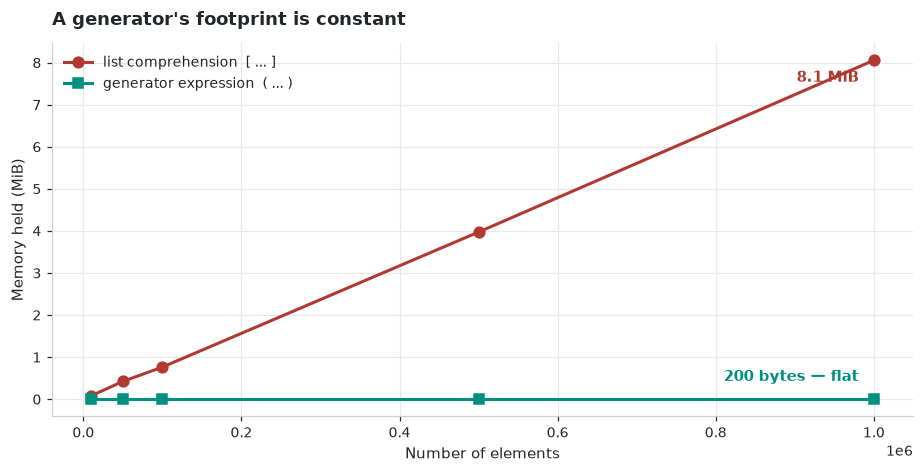

In [16]:
sizes = [10_000, 50_000, 100_000, 500_000, 1_000_000]

list_bytes = []
gen_bytes = []

for size in sizes:
    # A list comprehension materialises everything…
    materialised = [i * 1.5 for i in range(size)]
    # …while a generator expression (round brackets) does not.
    generator = (i * 1.5 for i in range(size))

    list_bytes.append(sys.getsizeof(materialised))
    gen_bytes.append(sys.getsizeof(generator))

fig, ax = plt.subplots(figsize=(8.5, 4.4))

ax.plot(sizes, np.array(list_bytes) / 1024**2, marker="o",
        label="list comprehension  [ ... ]", color=COLORS["danger"])
ax.plot(sizes, np.array(gen_bytes) / 1024**2, marker="s",
        label="generator expression  ( ... )", color=COLORS["teal"])

ax.set_xlabel("Number of elements")
ax.set_ylabel("Memory held (MiB)")
ax.set_title("A generator's footprint is constant")
ax.legend()

ax.annotate(
    f"{list_bytes[-1] / 1024**2:.1f} MiB",
    xy=(sizes[-1], list_bytes[-1] / 1024**2),
    xytext=(-10, -14), textcoords="offset points",
    ha="right", color=COLORS["danger"], fontweight="bold",
)
ax.annotate(
    f"{gen_bytes[-1]} bytes — flat",
    xy=(sizes[-1], gen_bytes[-1] / 1024**2),
    xytext=(-10, 12), textcoords="offset points",
    ha="right", color=COLORS["teal"], fontweight="bold",
)

fig.tight_layout()
plt.show()

### The realistic use: streaming a file

This is the pattern for any file too large to load. Note that the whole chain is
lazy — nothing is read until the final `for` loop pulls on it.

In [17]:
def parse_lines(lines):
    """Turn raw CSV-ish lines into dicts, lazily."""
    for line in lines:
        name, amount = line.strip().split(",")
        yield {"name": name, "amount": float(amount)}


def filter_large(records, minimum: float):
    """Keep only records above a threshold, lazily."""
    for record in records:
        if record["amount"] >= minimum:
            yield record


# Stand-in for a file object — a real one iterates line by line the same way.
raw_lines = [
    "ana,120.50\n", "bruno,45.00\n", "carla,890.25\n",
    "diego,12.75\n", "elena,340.00\n",
]

# Build the pipeline. No work has happened yet.
pipeline = filter_large(parse_lines(raw_lines), minimum=100)
print(f"pipeline object : {type(pipeline).__name__}  ← nothing computed yet\n")

# Only now does data start flowing, one record at a time.
for record in pipeline:
    print(f"  {record['name']:<8} {record['amount']:>8,.2f}")

pipeline object : generator  ← nothing computed yet

  ana        120.50
  carla      890.25
  elena      340.00


### Generator expressions

Identical to a list comprehension but with round brackets. Prefer them whenever
you are feeding a consumer such as `sum`, `max`, `any`, or `all`.

In [18]:
values = range(1_000_000)

# ✘ Builds a 1M-element list, then sums it and throws the list away.
total_eager = sum([v**2 for v in values])

# ✔ Streams values into sum, holding one at a time.
total_lazy = sum(v**2 for v in values)

print(f"same answer : {total_eager == total_lazy}")
print("The second never allocates the intermediate list.")

# `any` and `all` also short-circuit: they stop at the first decisive element.
print(f"\nany over 999,998? {any(v > 999_998 for v in values)}")

same answer : True
The second never allocates the intermediate list.

any over 999,998? True


> [!WARNING]
> A generator is **single-use**. Once exhausted it yields nothing more — and it
> does so silently, which makes this a nasty bug.

In [19]:
gen = (x for x in [1, 2, 3])

print(f"first pass  : {list(gen)}")
print(f"second pass : {list(gen)}   ← empty, not an error")

first pass  : [1, 2, 3]
second pass : []   ← empty, not an error


## 7. `map`, `filter`, `reduce`, and `lambda`

In [20]:
from functools import reduce

numbers = [1, 2, 3, 4, 5]

# `lambda` is a one-expression anonymous function. Use it only for short callables
# passed to another function; anything longer deserves a `def` and a name.
squared = list(map(lambda x: x**2, numbers))
evens = list(filter(lambda x: x % 2 == 0, numbers))
product = reduce(lambda acc, x: acc * x, numbers)

print(f"map    : {squared}")
print(f"filter : {evens}")
print(f"reduce : {product}")

# In idiomatic Python, comprehensions usually read better than map/filter:
print(f"\ncomprehension equivalents:")
print(f"  {[x**2 for x in numbers]}")
print(f"  {[x for x in numbers if x % 2 == 0]}")

map    : [1, 4, 9, 16, 25]
filter : [2, 4]
reduce : 120

comprehension equivalents:
  [1, 4, 9, 16, 25]
  [2, 4]


### `functools.partial` — pre-filling arguments

Creates a new function with some arguments already supplied. Very handy for
building small, named transformations to pass around.

In [21]:
def scale(value: float, *, factor: float, offset: float = 0.0) -> float:
    return value * factor + offset


to_fahrenheit = functools.partial(scale, factor=9 / 5, offset=32)
to_percent = functools.partial(scale, factor=100)

print(f"20°C  → {to_fahrenheit(20):.1f}°F")
print(f"0.734 → {to_percent(0.734):.1f}%")

20°C  → 68.0°F
0.734 → 73.4%


## 8. `itertools` — lazy iteration tools

In [22]:
import itertools

# chain: concatenate iterables without building a combined list.
batch_1, batch_2 = [1, 2], [3, 4]
print(f"chain       : {list(itertools.chain(batch_1, batch_2))}")

# islice: slice any iterable, including an infinite or streaming one.
print(f"islice      : {list(itertools.islice(itertools.count(10), 5))}")

# groupby: group CONSECUTIVE equal items — so sort by the key first!
records = [
    {"dept": "data", "name": "ana"},
    {"dept": "data", "name": "carla"},
    {"dept": "eng", "name": "bruno"},
]
print("groupby     :")
for dept, members in itertools.groupby(records, key=lambda r: r["dept"]):
    print(f"  {dept:<6} {[m['name'] for m in members]}")

# combinations / product: for grid searches and pairwise comparisons.
print(f"\ncombinations: {list(itertools.combinations(['a', 'b', 'c'], 2))}")
print(f"product     : {list(itertools.product([0.1, 0.5], ['l1', 'l2']))}")

chain       : [1, 2, 3, 4]
islice      : [10, 11, 12, 13, 14]
groupby     :
  data   ['ana', 'carla']
  eng    ['bruno']

combinations: [('a', 'b'), ('a', 'c'), ('b', 'c')]
product     : [(0.1, 'l1'), (0.1, 'l2'), (0.5, 'l1'), (0.5, 'l2')]


> [!TIP]
> `itertools.product` is exactly how a hyperparameter grid search enumerates its
> candidates. You will see it again — wrapped in `GridSearchCV` — in Module 13.

## 9. Pure functions and side effects

A **pure** function returns the same output for the same input and changes
nothing outside itself. Pure functions are trivially testable, safely
parallelisable, and cacheable.

In [23]:
# ✘ Impure: mutates its argument and depends on module state.
tax_rate = 0.2


def apply_tax_impure(order: dict) -> None:
    order["total"] = order["amount"] * (1 + tax_rate)


# ✔ Pure: everything it needs comes in; everything it produces comes out.
def apply_tax(order: dict, rate: float) -> dict:
    return {**order, "total": order["amount"] * (1 + rate)}


order = {"id": 1, "amount": 100.0}
taxed = apply_tax(order, rate=0.2)

print(f"input  : {order}   ← untouched")
print(f"output : {taxed}")

input  : {'id': 1, 'amount': 100.0}   ← untouched
output : {'id': 1, 'amount': 100.0, 'total': 120.0}


Not everything can be pure — reading files, writing to a database, and logging
are all side effects, and they are the point of the program. The professional
pattern is to **push side effects to the edges**: a thin impure shell that does
I/O, wrapped around a pure core that does the computation.

## 10. Exercises

### Exercise 4.1 — Fix the signature

```python
def summarise(data, True, 0.95, None):
    ...
```

Rewrite this as a well-designed signature with keyword-only options, defaults,
type hints, and a NumPy-style docstring. The function should compute summary
statistics with an optional confidence level and an optional column subset.

### Exercise 4.2 — Spot the trap

```python
def add_feature(df_columns, new_cols=[]):
    new_cols.append("engineered")
    return df_columns + new_cols
```

Call it three times with only the first argument. Explain the output, then fix it.

### Exercise 4.3 — Write a decorator

Write `@validate_positive` that raises `ValueError` if any *numeric* positional
argument passed to the decorated function is negative. Preserve the wrapped
function's metadata.

### Exercise 4.4 — Generator pipeline

Write three generators that chain together to process log lines:

1. `parse(lines)` → dicts with `level` and `message`;
2. `only_errors(records)` → keeps `level == "ERROR"`;
3. `take(records, n)` → yields at most `n` records.

Verify with `sys.getsizeof` that memory does not grow with the input size.

### Exercise 4.5 — Closure counter

Write `make_counter()` returning a function that yields 1, 2, 3, … on successive
calls, without using `global`. *Hint:* `nonlocal`.

## Key takeaways

- Make "mode" and boolean parameters **keyword-only** with `*`.
- **Never use a mutable default argument.** Use `None` as a sentinel.
- Type hints and NumPy-style docstrings are the ecosystem's conventions — follow them.
- Names resolve by **LEGB**; assignment inside a function makes a name local.
- A **decorator** wraps a function; always apply `functools.wraps`.
- `lru_cache` turns an expensive deterministic function into a lookup.
- **Generators trade time for memory** — constant footprint regardless of input
  size, and they are single-use.
- Prefer **pure functions**; push I/O and mutation to the edges of your program.

---

**Next:** [05 · Object-Oriented Programming](05_object_oriented_programming.ipynb)
— and how to write a class that plugs straight into a scikit-learn pipeline.